In [1]:
%reload_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore')
from IPython.display import clear_output

import pandas as pd
from functools import reduce
from tqdm.auto import tqdm
from pandarallel import pandarallel
pandarallel.initialize()

from rdkit import Chem
from rdkit.Chem import PandasTools
PandasTools.RenderImagesInAllDataFrames(images=True)
from rdkit.Chem.Draw import rdDepictor
rdDepictor.SetPreferCoordGen(True)
from rdkit import RDLogger; RDLogger.DisableLog('rdApp.*')

from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True
IPythonConsole.molSize = 600, 400
IPythonConsole.drawOptions.addAtomIndices = False

from new_geass import Geass
clear_output()

https://2025.igem.wiki/marburg/part-collection
https://www.biorxiv.org/content/biorxiv/early/2022/12/08/2022.12.02.518901.full.pdf#page=8.23
https://www.researchgate.net/figure/Examples-of-novel-peptides-produced-by-combinatorial-biosynthesis-via-engineering-NRPS_fig2_379934271
https://www.nature.com/articles/ncomms15349


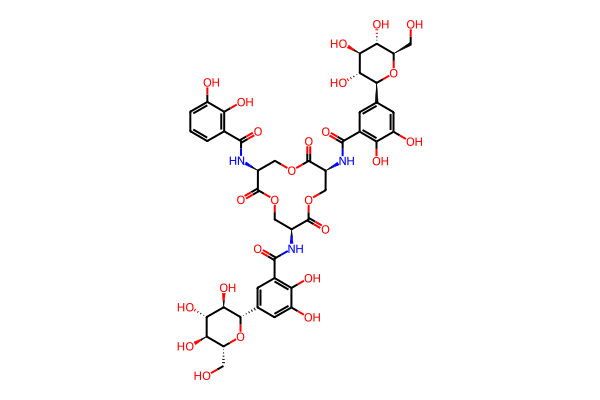

CytoscapeWidget(cytoscape_layout={'name': 'cola', 'nodeSpacing': 20, 'avoidOverlap': True, 'padding': 50, 'max…

In [3]:
smiles = ['CC[C@H](C)[C@@H](C(=O)N[C@H]1COC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC2=CC=C(C=C2)O)NC(=O)[C@@H](CC3=CC=C(C=C3)O)NC(=O)CCNC1=O)NC(=O)C',
          'C(C)(C)C[C@@H](C(=O)N[C@H]1COC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC2=CC=C(C=C2)O)NC(=O)[C@@H](CC3=CC=C(C=C3)O)NC(=O)CCNC1=O)NC(=O)C',
          'CCCCCCCCCC(O)CC(=O)N[C@@H](CO)C(=O)N[C@H]1COC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC2=CC=C(C=C2)O)NC(=O)[C@@H](CC3=CC=C(C=C3)O)NC(=O)CCNC1=O',
          'C/C=C/C=C/C=C/C=C/C=C/C=C/C=C/C=CC(=O)N(C)[C@@H]([C@H](O)C)C(=O)N[C@H]1COC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC2=CC=C(C=C2)O)NC(=O)[C@@H](CC3=CC=C(C=C3)O)NC(=O)CCNC1=O',
          # 'C1CCN(C(=O)CCC)[C@H]1C(=O)NCC(=O)N[C@H]1COC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC2=CC=C(C=C2)O)NC(=O)[C@@H](CC3=CC=C(C=C3)O)NC(=O)CCNC1=O',

          #  'CN1C[C@H]([C@@H]2[C@@H](C1=O)N=C(N2)NC3C(C(C(C(O3)CO)OC(=O)N)O)NC(=O)CC(CCCNC(=O)CC(CCCNC(=O)CC(CCCN)N)N)N)O'
          #  'Nc1ncnc2c1ncn2[C@@H]1O[C@H](COP(=O)(O)OP(=O)(O)OP(=O)(O)O)[C@@H](O)[C@H]1O'
        'C1[C@@H](C(=O)OC[C@@H](C(=O)OC[C@@H](C(=O)O1)NC(=O)C2=C(C(=CC(=C2)[C@H]3[C@@H]([C@H]([C@@H]([C@H](O3)CO)O)O)O)O)O)NC(=O)C4=C(C(=CC(=C4)[C@H]5[C@@H]([C@H]([C@@H]([C@H](O5)CO)O)O)O)O)O)NC(=O)C6=C(C(=CC=C6)O)O'
          ]

mol = Chem.MolFromSmiles(smiles[-1])
display(mol)

geass = Geass()
frags = geass.get_fragments(mol)
geass.show_connection_graph()

In [ ]:
display(*frags)

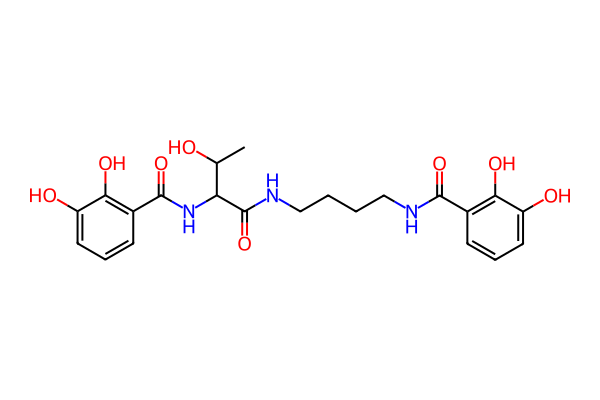

In [16]:
from rdkit.Chem import AllChem
rx = AllChem.ReactionFromSmarts(
    "[NR:0]=[CR:1]-[O,S;R:2]>>([N:0]-[C:1]=O.[O,S:2])")
    # "[c:0]-[C;$(C(=N)[O,S]):1]>>([c:0].[C:1])")
matches = mol.GetSubstructMatches(Chem.Mol(rx.GetReactantTemplate(0).ToBinary()))
mol
display(*rx.RunReactants((mol,))[0])

In [ ]:
from annotator import AnnotationEngine
AnnotationEngine.initialize_resources()
annotator = AnnotationEngine()

df = UUDB.sample(50).copy()
df['ISOSMILES_SS'] = df['ROMol'].apply(annotator.find_similar)
PandasTools.AddMoleculeColumnToFrame(df, 'ISOSMILES_SS', 'ROMol_SS')
PandasTools.AddMoleculeColumnToFrame(df, 'ISOSMILES_Similar', 'ROMol_Similar')
df

In [ ]:
import sys
sys.path.append('/home/mattia/aiddtools')
import fingerprint_tools as fpt

# molecule 1
mol1 = Chem.MolFromSmiles("CC(C)C(N)C(=O)CN")
mol2 = Chem.MolFromSmiles("CC(C)[C@H](N)C(=O)O")

fp1 = fpt.calculate_fp(mol1, 'pubchem', as_numpy=True)
fp2 = fpt.calculate_fp(mol2, 'pubchem', as_numpy=True)

sim = fpt.calculate_similarity(fp1, fp2, 'pubchem')
sim

In [ ]:
pd.read_pickle('data/MUDB.pkl')

In [ ]:
df_MUDB = pd.read_pickle('data/MUDB.pkl')

fps = []

for mol in df_MUDB['ROMol']:
    try:
        fp = fpt.calculate_fp(mol, 'pubchem', as_numpy=True)
    except Exception:
        fp = None
    fps.append(fp)

df_MUDB['FP_pubchem'] = fps


df_MUDB.to_pickle('data/MUDB.pkl')
df_MUDB

In [ ]:
# df_MUDB.drop(columns='FP_pubchem').to_pickle('data/MUDB.pkl')
# import numpy as np

# def bitset_to_numpy(fp):
#     if fp is None:
#         return None
#     return np.fromiter(
#         (1 if fp.test(i) else 0 for i in range(fp.getSize())),
#         dtype=np.uint8,
#         count=fp.getSize()
#     )

# df_MUDB['FP_pubchem'] = df_MUDB['FP_pubchem'].apply(bitset_to_numpy)

df_MUDB.to_pickle('data/MUDB1.pkl')